In [2]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "1"   # arriba del todo, antes de importar numpy (reinicia el kernel)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utils.tv_var.harmonic_standardizer import HarmonicStandardizer

from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor

#### Load Data

In [3]:
#### PCS
pcs_msl = pd.read_csv('outputs/pca/pcs_msl.csv', index_col=0, parse_dates=True)
pcs_msl_gradient = pd.read_csv('outputs/pca/pcs_msl_gradient.csv', index_col=0, parse_dates=True)
pcs_all = pcs_msl.join(pcs_msl_gradient)
#### Waves
waves_df = pd.read_csv('inputs/waves_bulk.csv', index_col=0, parse_dates=True)
harm_std = HarmonicStandardizer(n_harmonics=3)
harm_std.fit(waves_df.loc['1985-01-01':'2015-12-31'])
waves_df_z = harm_std.transform(waves_df)
#### 6-horario: PCs en 00, 06, 12, 18 h; Z = media de 6 h centrada
horas_6h = [0, 6, 12, 18]
pcs_all_6h = pcs_all[pcs_all.index.hour.isin(horas_6h)]
waves_df_z_6h = waves_df_z.rolling("6h", center=True).mean()
waves_df_z_6h = waves_df_z_6h[waves_df_z_6h.index.hour.isin(horas_6h)].dropna()
print(pcs_all_6h.shape, waves_df_z_6h.shape)

(126864, 63) (60992, 2)


In [4]:
pcs_msl_train = pcs_all_6h.loc['1985-01-01':'2015-12-31']
pcs_msl_predict = pcs_all_6h.loc['2016-01-01':'2025-12-31']
waves_df_train = waves_df_z_6h.loc['1985-01-01':'2015-12-31']
waves_df_predict = waves_df_z_6h.loc['2016-01-01':'2025-12-31']
waves_df_predict_h = waves_df_z.loc['2016-01-01':'2025-12-31']      # Z horaria, para evaluar

#### Lasso

In [5]:
lags = [0, 6, 12, 18, 24, 30, 36]
pcs_msl_train_lagged = pd.concat({f"l{l}": pcs_msl_train.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs_msl_train.index)
pcs_msl_train_lagged.columns = [f"{c}_l{l[1:]}" for l, c in pcs_msl_train_lagged.columns]
pcs_msl_train_lagged = pcs_msl_train_lagged.dropna()
pcs_msl_train_lagged = pcs_msl_train_lagged.loc[pcs_msl_train_lagged.index.intersection(waves_df_train.index)]         
print(pcs_msl_train_lagged.shape)  

(45282, 441)


In [6]:
lags = [0, 6, 12, 18, 24, 30, 36]
pcs_msl_predict_lagged = pd.concat({f"l{l}": pcs_msl_predict.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs_msl_predict.index)
pcs_msl_predict_lagged.columns = [f"{c}_l{l[1:]}" for l, c in pcs_msl_predict_lagged.columns]
pcs_msl_predict_lagged = pcs_msl_predict_lagged.dropna()
pcs_msl_predict_lagged = pcs_msl_predict_lagged.loc[pcs_msl_predict_lagged.index.intersection(waves_df_predict.index)]         
print(pcs_msl_predict_lagged.shape)  

waves_df_predict = waves_df_predict.loc[pcs_msl_predict_lagged.index.values]

(14606, 441)


In [7]:
X = pcs_msl_train_lagged.values
Xs = StandardScaler().fit_transform(X)  

y = waves_df_train.loc[pcs_msl_train_lagged.index.values]['VHM0'].values
lasso_cv = LassoCV(cv=5, random_state=0).fit(X=Xs, y=y)

c:\Users\alonsoap\.conda\envs\tv_var\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.849499e+01, tolerance: 4.412e+00
  model = cd_fast.enet_coordinate_descent(


In [8]:
# Access the best alpha and coefficients
print("Best Alpha:", lasso_cv.alpha_)
print("Coefficients:", lasso_cv.coef_)
print("R^2 Score:", lasso_cv.score(Xs, y))

Best Alpha: 0.0003378816415559501
Coefficients: [ 5.26066168e-03  2.60900164e-02  0.00000000e+00  0.00000000e+00
  5.37880511e-03  8.22047004e-02  4.67975274e-02 -2.35646088e-02
  5.09909093e-02  1.60873637e-03  5.56063476e-02 -8.98287137e-02
 -6.13034991e-02  9.13203640e-02  1.17553746e-01  1.28645596e-01
 -3.27651592e-02 -9.01885091e-02 -3.82719430e-02  0.00000000e+00
 -1.06046741e-03 -6.49953430e-02 -3.68533041e-02  2.57393305e-02
 -9.07442215e-02  0.00000000e+00  5.30635656e-03 -5.10698332e-02
  1.88847343e-02  5.27566318e-03  3.86817195e-02  2.19108622e-02
 -1.37716847e-02  3.75722121e-02 -1.64585172e-02  1.26322928e-02
 -3.16855018e-02 -2.40079244e-02 -3.04708233e-03 -3.34388494e-03
 -1.84339018e-03 -3.23667340e-03  1.72025732e-02  1.42725375e-02
  6.66396643e-03 -6.23177045e-02 -4.53168395e-03  2.58428324e-02
 -9.53310315e-03  1.36037406e-03  3.76147597e-02  7.90226081e-03
 -0.00000000e+00  1.04556161e-04 -4.05705035e-03 -5.92668140e-02
  3.83715265e-02 -3.97020640e-02  3.178488

pc,grad_PC1,grad_PC2,grad_PC3,grad_PC4,grad_PC5,grad_PC6,grad_PC7,grad_PC8,grad_PC9,grad_PC10,...,msl_PC4,msl_PC5,msl_PC6,msl_PC7,msl_PC8,msl_PC9,msl_PC10,msl_PC11,msl_PC12,msl_PC13
lag,,,,,,,,,,,,,,,,,,,,,
0,0.091,0.118,0.129,-0.033,-0.090,-0.038,0.000,-0.001,-0.065,-0.037,...,0.000,0.005,0.082,0.047,-0.024,0.051,0.002,0.056,-0.090,-0.061
6,0.104,0.042,0.077,-0.042,-0.046,-0.022,-0.000,-0.000,-0.027,-0.023,...,0.025,-0.000,-0.000,-0.000,-0.054,-0.013,0.021,-0.000,0.046,0.130
12,0.096,0.081,0.089,-0.070,-0.074,-0.019,-0.044,-0.008,-0.054,-0.037,...,0.000,-0.029,-0.013,-0.000,-0.000,-0.000,0.000,-0.032,0.000,0.033
18,0.027,0.054,0.029,-0.006,-0.048,-0.023,-0.020,0.000,-0.044,-0.024,...,0.000,0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,-0.007,-0.010
24,0.000,0.000,-0.000,-0.002,-0.004,0.000,-0.003,0.019,-0.010,-0.001,...,0.000,0.010,0.008,-0.000,0.046,-0.030,0.003,0.003,0.000,-0.011
30,0.000,-0.000,-0.006,-0.000,-0.041,-0.000,-0.000,0.000,-0.012,-0.000,...,0.000,0.000,0.047,-0.000,0.026,-0.000,0.025,0.045,0.001,0.000
36,0.000,0.026,0.007,-0.000,-0.037,-0.003,0.003,0.032,0.015,-0.016,...,0.048,-0.000,0.053,-0.025,-0.030,-0.024,0.000,0.031,-0.026,0.003


suma |coef| por PC:
 pc
msl_PC2      0.419
grad_PC5     0.339
grad_PC3     0.336
grad_PC2     0.320
grad_PC1     0.318
msl_PC3      0.256
msl_PC13     0.249
grad_PC12    0.230
grad_PC9     0.227
msl_PC1      0.225
grad_PC11    0.217
msl_PC6      0.203
grad_PC16    0.183
grad_PC33    0.183
msl_PC8      0.180
grad_PC35    0.173
msl_PC12     0.169
msl_PC11     0.168
grad_PC4     0.153
grad_PC23    0.147
grad_PC15    0.140
grad_PC10    0.138
grad_PC44    0.122
grad_PC20    0.119
grad_PC22    0.118
msl_PC9      0.118
grad_PC14    0.109
grad_PC6     0.105
grad_PC43    0.101
grad_PC18    0.097
grad_PC29    0.092
grad_PC30    0.086
grad_PC21    0.086
grad_PC48    0.081
grad_PC45    0.079
msl_PC4      0.073
grad_PC17    0.072
msl_PC7      0.071
grad_PC38    0.071
grad_PC7     0.070
grad_PC46    0.065
grad_PC25    0.063
grad_PC26    0.062
grad_PC19    0.060
grad_PC8     0.060
grad_PC50    0.059
grad_PC32    0.059
msl_PC10     0.051
grad_PC24    0.050
grad_PC36    0.048
grad_PC13    0.047
msl_PC5

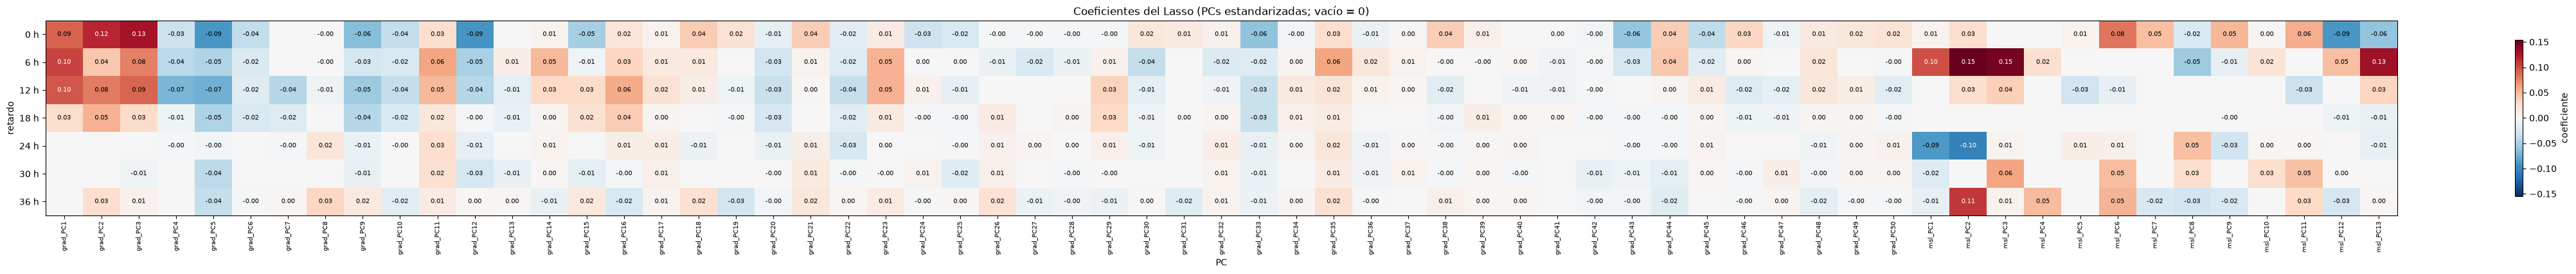

In [11]:
cols = pcs_msl_train_lagged.columns                            # p. ej. "msl_PC4_l12"
coef = pd.Series(lasso_cv.coef_, index=cols)                      # tu modelo Lasso ajustado
M = pd.DataFrame({"pc": [c.rsplit("_l", 1)[0] for c in cols],      # "msl_PC4" / "grad_PC4" (prefijo incluido: PC4 existe en ambas familias)
                  "lag": [int(c.rsplit("_l", 1)[1]) for c in cols],
                  "coef": coef.values})
M = M.pivot(index="lag", columns="pc", values="coef")

def _pc_key(s):
    fam, num = s.rsplit("_PC", 1)
    return (fam, int(num))

M = M[sorted(M.columns, key=_pc_key)].sort_index()

lim = np.abs(M.values).max()
fig, ax = plt.subplots(figsize=(1.0 + 0.62 * M.shape[1], 1.0 + 0.45 * M.shape[0]), constrained_layout=True)
im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.iloc[i, j]
        if v != 0:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(v) > 0.6 * lim else "black")
ax.set_xticks(range(M.shape[1]), M.columns, rotation=90, fontsize=7)
ax.set_yticks(range(M.shape[0]), [f"{l} h" for l in M.index])
ax.set(xlabel="PC", ylabel="retardo", title="Coeficientes del Lasso (PCs estandarizadas; vacío = 0)")
fig.colorbar(im, ax=ax, shrink=0.8, label="coeficiente")
display(M.round(3))
print("suma |coef| por PC:\n", M.abs().sum().sort_values(ascending=False).round(3).to_string())


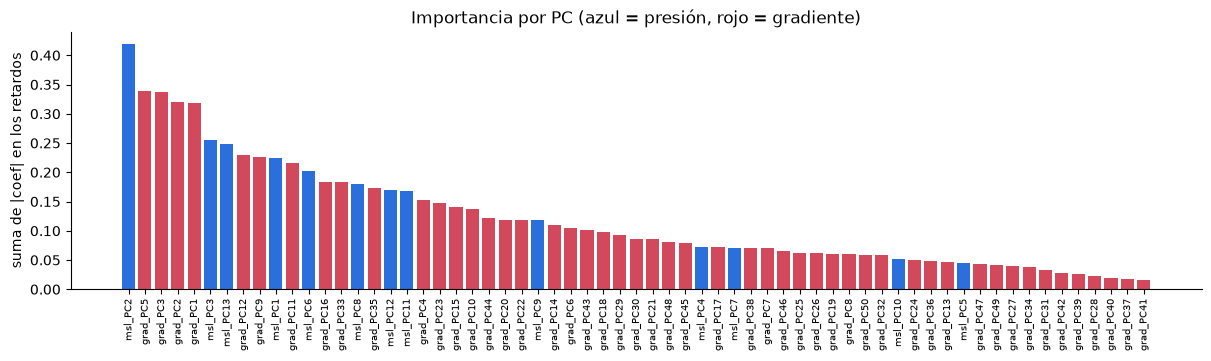

In [10]:
imp = M.abs().sum().sort_values(ascending=False)                      # suma de |coef| por PC
fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.bar(range(len(imp)), imp.values,
       color=["#2a6fdb" if n.startswith("msl") else "#d1495b" for n in imp.index])
ax.set_xticks(range(len(imp)), imp.index, rotation=90, fontsize=7)
ax.set(ylabel="suma de |coef| en los retardos", title="Importancia por PC (azul = presión, rojo = gradiente)")
ax.spines[["top", "right"]].set_visible(False)

In [ ]:
xgboost_model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200, 
                             subsample=0.8, colsample_bytree=0.8,
                       tree_method="hist", n_jobs=-1, random_state=0
)

In [19]:
xgboost_model.fit(pcs_msl_train_lagged.values, y)
y_model = pd.Series(xgboost_model.predict(pcs_msl_predict_lagged.values), index=pcs_msl_predict_lagged.index)
y_model_h = y_model.resample("h").interpolate()                       # f 6-horaria → horaria

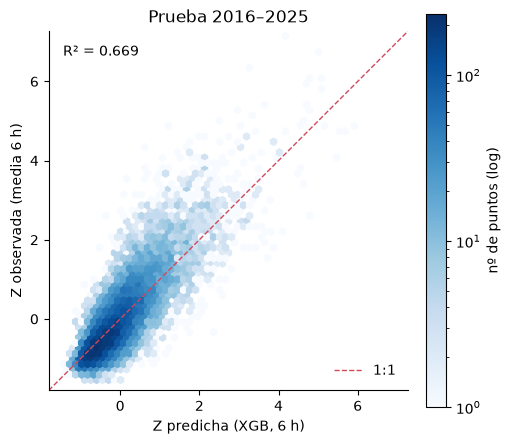

In [20]:
obs = waves_df_predict.loc[y_model.index]['VHM0'].values
pred = y_model.values
lim = [min(obs.min(), pred.min()) - 0.2, max(obs.max(), pred.max()) + 0.2]

fig, ax = plt.subplots(figsize=(5, 5), constrained_layout=True)
hb = ax.hexbin(pred, obs, gridsize=60, bins="log", cmap="Blues", mincnt=1, extent=lim + lim)
ax.plot(lim, lim, color="#d1495b", lw=1, ls="--", label="1:1")
ax.set(xlim=lim, ylim=lim, aspect="equal",
       xlabel="Z predicha (XGB, 6 h)", ylabel="Z observada (media 6 h)",
       title="Prueba 2016–2025")
ax.text(0.04, 0.96, f"R² = {r2_score(obs, pred):.3f}", transform=ax.transAxes, va="top")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(hb, ax=ax, shrink=0.8, label="nº de puntos (log)")

In [21]:
from sklearn.metrics import r2_score

obs = waves_df_predict.loc[y_model.index]['VHM0'].values             # Z 6-horaria (media de 6 h)
print(f"R² 6-horario (prueba): {r2_score(obs, y_model.values):.3f}")

obs_h = waves_df_predict_h['VHM0'].reindex(y_model_h.index).dropna()  # Z horaria observada
print(f"R² horario (prueba):   {r2_score(obs_h, y_model_h.loc[obs_h.index]):.3f}")

# en escala diaria, la de tu objetivo de cronología
d = pd.DataFrame({"obs": obs_h, "pred": y_model_h.loc[obs_h.index]}).resample("D").mean().dropna()
print(f"R² diario (prueba):    {r2_score(d.obs, d.pred):.3f}")
print(f"correlación diaria:    {d.obs.corr(d.pred):.3f}")

R² 6-horario (prueba): 0.669
R² horario (prueba):   0.657
R² diario (prueba):    0.730
correlación diaria:    0.857


 1 PCs (+msl_PC2): R² = 0.084   (1 s)
 2 PCs (+grad_PC5): R² = 0.210   (1 s)
 3 PCs (+grad_PC3): R² = 0.317   (1 s)
 4 PCs (+grad_PC2): R² = 0.370   (1 s)
 5 PCs (+grad_PC1): R² = 0.390   (1 s)
 6 PCs (+msl_PC3): R² = 0.399   (2 s)
 7 PCs (+msl_PC13): R² = 0.420   (2 s)
 8 PCs (+grad_PC12): R² = 0.468   (3 s)
 9 PCs (+grad_PC9): R² = 0.494   (3 s)
10 PCs (+msl_PC1): R² = 0.499   (3 s)
11 PCs (+grad_PC11): R² = 0.514   (3 s)
12 PCs (+msl_PC6): R² = 0.521   (3 s)
13 PCs (+grad_PC16): R² = 0.536   (4 s)
14 PCs (+grad_PC33): R² = 0.555   (5 s)
15 PCs (+msl_PC8): R² = 0.558   (5 s)
18 PCs (+msl_PC11): R² = 0.577   (6 s)
21 PCs (+grad_PC15): R² = 0.599   (7 s)
24 PCs (+grad_PC20): R² = 0.612   (8 s)
27 PCs (+grad_PC14): R² = 0.618   (9 s)
30 PCs (+grad_PC18): R² = 0.618   (11 s)
33 PCs (+grad_PC21): R² = 0.631   (13 s)
36 PCs (+msl_PC4): R² = 0.643   (14 s)
39 PCs (+grad_PC38): R² = 0.645   (16 s)
42 PCs (+grad_PC25): R² = 0.646   (17 s)
45 PCs (+grad_PC8): R² = 0.649   (18 s)
48 PCs (+msl_P

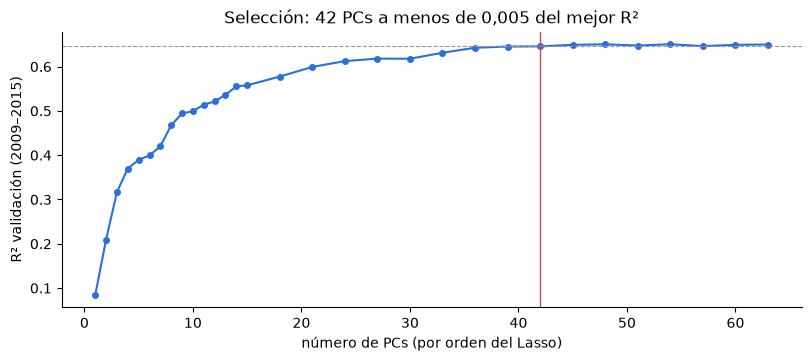

In [22]:
import time
from sklearn.metrics import r2_score

orden = imp.index.tolist()                                # PCs ordenadas por el Lasso
Xall, yall = pcs_msl_train_lagged, pd.Series(y, index=pcs_msl_train_lagged.index)
tr = Xall.index < "2009-01-01"                            # ajuste interno
va = ~tr                                                  # validación interna (2009–2015)

def r2_con(pcs):
    cols = [c for c in Xall.columns if c.rsplit("_l", 1)[0] in pcs]
    m = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, min_child_weight=200,
                     subsample=0.8, colsample_bytree=0.8, tree_method="hist", n_jobs=32, random_state=0)
    m.fit(Xall.loc[tr, cols], yall[tr])
    return r2_score(yall[va], m.predict(Xall.loc[va, cols]))

ks = list(range(1, 16)) + list(range(18, len(orden) + 1, 3))
if ks[-1] != len(orden):
    ks.append(len(orden))
curva = {}
for k in ks:
    t = time.time()
    curva[k] = r2_con(orden[:k])
    print(f"{k:>2} PCs (+{orden[k-1]}): R² = {curva[k]:.3f}   ({time.time() - t:.0f} s)")

curva = pd.Series(curva)
k_min = int(curva.index[curva >= curva.max() - 0.005][0])     # menos PCs a ≤ 0,005 del máximo
fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(curva.index, curva.values, "o-", color="#2a6fdb", ms=4)
ax.axhline(curva.max() - 0.005, color="0.6", lw=0.8, ls="--")
ax.axvline(k_min, color="#d1495b", lw=1)
ax.set(xlabel="número de PCs (por orden del Lasso)", ylabel="R² validación (2009–2015)",
       title=f"Selección: {k_min} PCs a menos de 0,005 del mejor R²")
ax.spines[["top", "right"]].set_visible(False)
seleccion = orden[:k_min]
print(seleccion)

In [ ]:
seleccion = orden[:39]
r2_base = r2_con(seleccion)

perdida = {}
for pc in seleccion:
    t = time.time()
    perdida[pc] = r2_base - r2_con([p for p in seleccion if p != pc])
    print(f"sin {pc:>10}: ΔR² = {perdida[pc]:+.3f}   ({time.time() - t:.0f} s)")

perdida = pd.Series(perdida).sort_values()
print(f"\nR² con las 39: {r2_base:.3f}")
print(perdida.round(3).to_string())

sin    msl_PC2: ΔR² = +0.020   (14 s)
sin   grad_PC5: ΔR² = +0.012   (14 s)
sin   grad_PC3: ΔR² = +0.017   (14 s)
sin   grad_PC2: ΔR² = +0.009   (15 s)
sin   grad_PC1: ΔR² = +0.001   (15 s)
sin    msl_PC3: ΔR² = +0.004   (14 s)
sin   msl_PC13: ΔR² = +0.004   (15 s)
sin  grad_PC12: ΔR² = +0.003   (15 s)
sin   grad_PC9: ΔR² = +0.009   (14 s)
sin    msl_PC1: ΔR² = +0.002   (14 s)
sin  grad_PC11: ΔR² = +0.003   (14 s)
sin    msl_PC6: ΔR² = +0.001   (15 s)
sin  grad_PC16: ΔR² = +0.010   (14 s)
sin  grad_PC33: ΔR² = +0.008   (15 s)
sin    msl_PC8: ΔR² = +0.003   (15 s)
sin  grad_PC35: ΔR² = +0.006   (14 s)
sin   msl_PC12: ΔR² = +0.002   (15 s)
sin   msl_PC11: ΔR² = +0.003   (15 s)
sin   grad_PC4: ΔR² = +0.006   (15 s)
sin  grad_PC23: ΔR² = +0.006   (15 s)
sin  grad_PC15: ΔR² = +0.002   (15 s)
sin  grad_PC10: ΔR² = +0.008   (17 s)
sin  grad_PC44: ΔR² = +0.004   (15 s)
sin  grad_PC20: ΔR² = +0.000   (15 s)
sin  grad_PC22: ΔR² = -0.001   (15 s)
sin    msl_PC9: ΔR² = -0.002   (15 s)
sin  grad_PC

In [34]:
grad_sel = [2, 3, 4, 5, 9, 10, 11, 12, 14, 16, 21, 23, 33, 35, 43, 44, 48]
seleccion_final = [f"msl_PC{i}" for i in range(1, 14)] + [f"grad_PC{i}" for i in grad_sel]

print(f"R² con las 39:            {r2_base:.3f}")
print(f"R² con las {len(seleccion_final)} finales:    {r2_con(seleccion_final):.3f}")

R² con las 39:            0.645
R² con las 30 finales:    0.636


In [35]:
cols_final = [c for c in pcs_msl_train_lagged.columns if c.rsplit("_l", 1)[0] in seleccion_final]
xgboost_model.fit(pcs_msl_train_lagged[cols_final].values, y)
y_model = pd.Series(xgboost_model.predict(pcs_msl_predict_lagged[cols_final].values), index=pcs_msl_predict_lagged.index)
y_model_h = y_model.resample("h").interpolate()

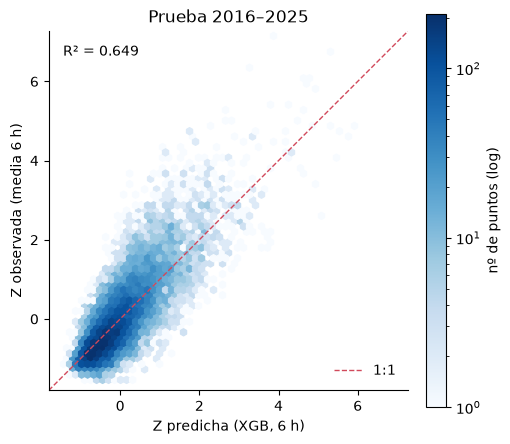

In [36]:
obs = waves_df_predict.loc[y_model.index]['VHM0'].values
pred = y_model.values
lim = [min(obs.min(), pred.min()) - 0.2, max(obs.max(), pred.max()) + 0.2]

fig, ax = plt.subplots(figsize=(5, 5), constrained_layout=True)
hb = ax.hexbin(pred, obs, gridsize=60, bins="log", cmap="Blues", mincnt=1, extent=lim + lim)
ax.plot(lim, lim, color="#d1495b", lw=1, ls="--", label="1:1")
ax.set(xlim=lim, ylim=lim, aspect="equal",
       xlabel="Z predicha (XGB, 6 h)", ylabel="Z observada (media 6 h)",
       title="Prueba 2016–2025")
ax.text(0.04, 0.96, f"R² = {r2_score(obs, pred):.3f}", transform=ax.transAxes, va="top")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(hb, ax=ax, shrink=0.8, label="nº de puntos (log)")

In [37]:
from sklearn.metrics import r2_score

obs = waves_df_predict.loc[y_model.index]['VHM0'].values             # Z 6-horaria (media de 6 h)
print(f"R² 6-horario (prueba): {r2_score(obs, y_model.values):.3f}")

obs_h = waves_df_predict_h['VHM0'].reindex(y_model_h.index).dropna()  # Z horaria observada
print(f"R² horario (prueba):   {r2_score(obs_h, y_model_h.loc[obs_h.index]):.3f}")

# en escala diaria, la de tu objetivo de cronología
d = pd.DataFrame({"obs": obs_h, "pred": y_model_h.loc[obs_h.index]}).resample("D").mean().dropna()
print(f"R² diario (prueba):    {r2_score(d.obs, d.pred):.3f}")
print(f"correlación diaria:    {d.obs.corr(d.pred):.3f}")

R² 6-horario (prueba): 0.649
R² horario (prueba):   0.637
R² diario (prueba):    0.710
correlación diaria:    0.845


In [38]:
import json
os.makedirs("outputs/seleccion_6h", exist_ok=True)

# 1. PCs seleccionadas, 6-horarias, 1940–2026 (para el VAR)
pcs_sel_6h = pcs_all_6h[seleccion_final]
pcs_sel_6h.to_csv("outputs/seleccion_6h/pcs_seleccionadas_6h.csv")

# 2. Lista de PCs y retardos usados
with open("outputs/seleccion_6h/seleccion.json", "w") as f:
    json.dump({"pcs": seleccion_final, "lags_h": lags}, f, indent=1)

# 3. XGB entrenado con las 30 PCs (f de la primera etapa)
xgboost_model.save_model("outputs/seleccion_6h/xgb_f_6h.json")

print(pcs_sel_6h.shape, pcs_sel_6h.index[0], pcs_sel_6h.index[-1])

(126864, 30) 1940-01-01 00:00:00 2026-10-31 18:00:00
